<a href="https://colab.research.google.com/github/elvirabilqis/05-02-2026/blob/main/Analisis_Data_Penjualan.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style('whitegrid')
rupiah = lambda x: f"{x:,.0f}".replace(",", ".")

from google.colab import files
files.upload()   # pilih online_sales_dataset.csv

df = pd.read_csv('online_sales_dataset.csv')
df.head()

Saving online_sales_dataset.csv to online_sales_dataset (1).csv


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,Discount,PaymentMethod,ShippingCost,Category,SalesChannel,ReturnStatus,ShipmentProvider,WarehouseLocation,OrderPriority
0,221958,SKU_1964,White Mug,38,2020-01-01 00:00,1.71,37039.0,Australia,0.470000,Bank Transfer,10.79,Apparel,In-store,Not Returned,UPS,London,Medium
1,771155,SKU_1241,White Mug,18,2020-01-01 01:00,41.25,19144.0,Spain,0.190000,paypall,9.51,Electronics,Online,Not Returned,UPS,Rome,Medium
2,231932,SKU_1501,Headphones,49,2020-01-01 02:00,29.11,50472.0,Germany,0.350000,Bank Transfer,23.03,Electronics,Online,Returned,UPS,Berlin,High
3,465838,SKU_1760,Desk Lamp,14,2020-01-01 03:00,76.68,96586.0,Netherlands,0.140000,paypall,11.08,Accessories,Online,Not Returned,Royal Mail,Rome,Low
4,359178,SKU_1386,USB Cable,-30,2020-01-01 04:00,-68.11,NaN,United Kingdom,1.501433,Bank Transfer,NaN,Electronics,In-store,Not Returned,FedEx,NaN,Medium


In [ ]:
n_awal = len(df)
df = df.drop_duplicates()
df['PaymentMethod'] = df['PaymentMethod'].replace({'paypall': 'PayPal'})
df['WarehouseLocation'] = df['WarehouseLocation'].fillna('Tidak Diketahui')
df['ShippingCost'] = df['ShippingCost'].fillna(df['ShippingCost'].median())
df['InvoiceDate'] = pd.to_datetime(df['InvoiceDate'])

# buang transaksi tidak valid
valid = (df['Quantity'] > 0) & (df['UnitPrice'] > 0) & (df['Discount'] <= 1)
n_invalid = (~valid).sum()
df = df[valid].copy()

# kolom turunan
df['Total'] = df['Quantity'] * df['UnitPrice'] * (1 - df['Discount'])
df['Bulan'] = df['InvoiceDate'].dt.to_period('M')
df['Tahun'] = df['InvoiceDate'].dt.year

print(f'Baris awal           : {n_awal}')
print(f'Baris tidak valid    : {n_invalid} (dibuang)')
print(f'Baris bersih dipakai : {len(df)}')

Baris awal           : 49782
Baris tidak valid    : 2489 (dibuang)
Baris bersih dipakai : 47293


In [ ]:
n_awal = len(df)
df = df.drop_duplicates()
df['PaymentMethod'] = df['PaymentMethod'].replace({'paypall': 'PayPal'})
df['WarehouseLocation'] = df['WarehouseLocation'].fillna('Tidak Diketahui')
df['ShippingCost'] = df['ShippingCost'].fillna(df['ShippingCost'].median())
df['InvoiceDate'] = pd.to_datetime(df['InvoiceDate'])

# buang transaksi tidak valid
valid = (df['Quantity'] > 0) & (df['UnitPrice'] > 0) & (df['Discount'] <= 1)
n_invalid = (~valid).sum()
df = df[valid].copy()

# kolom turunan
df['Total'] = df['Quantity'] * df['UnitPrice'] * (1 - df['Discount'])
df['Bulan'] = df['InvoiceDate'].dt.to_period('M')
df['Tahun'] = df['InvoiceDate'].dt.year

print(f'Baris awal           : {n_awal}')
print(f'Baris tidak valid    : {n_invalid} (dibuang)')
print(f'Baris bersih dipakai : {len(df)}')

Baris awal           : 47293
Baris tidak valid    : 0 (dibuang)
Baris bersih dipakai : 47293


In [ ]:
total_jual = df['Total'].sum()
rata_trx   = df['Total'].mean()
median_trx = df['Total'].median()
std_trx    = df['Total'].std()
q1, q3     = df['Total'].quantile([0.25, 0.75])
iqr        = q3 - q1

per_kategori = df.groupby('Category')['Total'].sum().sort_values(ascending=False)
qty_kategori = df.groupby('Category')['Quantity'].sum().sort_values(ascending=False)
per_negara   = df.groupby('Country')['Total'].sum().sort_values(ascending=False)
rate_return  = (df['ReturnStatus'] == 'Returned').mean() * 100

print(f'Total Penjualan        : {rupiah(total_jual)}')
print(f'Rata-rata Transaksi    : {rata_trx:,.2f}')
print(f'Median Transaksi       : {median_trx:,.2f}')
print(f'Standar Deviasi        : {std_trx:,.2f}')
print(f'Q1 / Q3 / IQR          : {q1:,.2f} / {q3:,.2f} / {iqr:,.2f}')
print(f'Kategori Terlaris (qty): {qty_kategori.index[0]} ({qty_kategori.iloc[0]} unit)')
print(f'Pendapatan tertinggi   : {per_kategori.index[0]} ({per_kategori.iloc[0]:,.0f})')
print(f'Pendapatan terendah    : {per_kategori.index[-1]} ({per_kategori.iloc[-1]:,.0f})')
print(f'Negara teratas         : {per_negara.index[0]} ({per_negara.iloc[0]:,.0f})')
print(f'Negara terendah        : {per_negara.index[-1]} ({per_negara.iloc[-1]:,.0f})')
print(f'Rata-rata diskon       : {df["Discount"].mean()*100:.1f}%')
print(f'Tingkat retur          : {rate_return:.2f}%')
print(f'Korelasi Qty vs Total  : {df["Quantity"].corr(df["Total"]):.3f}')

Total Penjualan        : 44.633.694
Rata-rata Transaksi    : 943.77
Median Transaksi       : 691.25
Standar Deviasi        : 851.75
Q1 / Q3 / IQR          : 260.00 / 1,403.52 / 1,143.52
Kategori Terlaris (qty): Furniture (238212 unit)
Pendapatan tertinggi   : Furniture (9,029,879)
Pendapatan terendah    : Stationery (8,870,610)
Negara teratas         : Belgium (3,834,826)
Negara terendah        : Netherlands (3,573,518)
Rata-rata diskon       : 25.0%
Tingkat retur          : 9.82%
Korelasi Qty vs Total  : 0.630


In [ ]:
batas_bawah = q1 - 1.5 * iqr
batas_atas  = q3 + 1.5 * iqr
outlier = df[(df['Total'] < batas_bawah) | (df['Total'] > batas_atas)]

print(f'Batas bawah / atas : {batas_bawah:,.2f} / {batas_atas:,.2f}')
print(f'Jumlah outlier     : {len(outlier)} ({len(outlier)/len(df)*100:.2f}%)')
print('\nOutlier per kategori:')
print(outlier['Category'].value_counts())
print('\nRata-rata Quantity  outlier :', round(outlier['Quantity'].mean(), 1))
print('Rata-rata UnitPrice outlier :', round(outlier['UnitPrice'].mean(), 1))
print('Rata-rata Discount  outlier :', round(outlier['Discount'].mean(), 3),
      '| non-outlier:', round(df.drop(outlier.index)['Discount'].mean(), 3))
outlier.nlargest(5, 'Total')[['Category','Quantity','UnitPrice','Discount','Total']]

Batas bawah / atas : -1,455.28 / 3,118.80
Jumlah outlier     : 1184 (2.50%)

Outlier per kategori:
Category
Furniture      271
Electronics    240
Stationery     230
Apparel        224
Accessories    219
Name: count, dtype: int64

Rata-rata Quantity  outlier : 44.3
Rata-rata UnitPrice outlier : 89.5
Rata-rata Discount  outlier : 0.104 | non-outlier: 0.254


,Category,Quantity,UnitPrice,Discount,Total
6204,Apparel,49,99.92,0.01,4847.1192
33826,Apparel,49,97.09,0.01,4709.8359
18473,Stationery,49,98.75,0.03,4693.5875
31077,Accessories,49,99.42,0.04,4676.7168
3075,Accessories,49,96.88,0.02,4652.1776


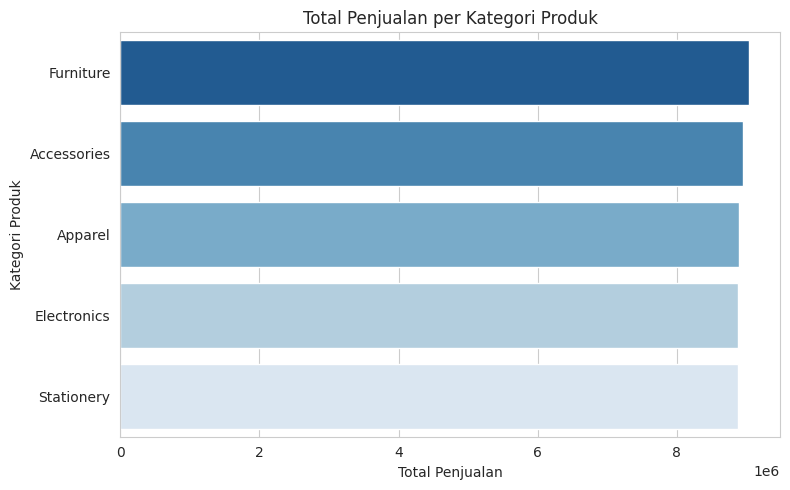

In [ ]:
plt.figure(figsize=(8,5))
sns.barplot(x=per_kategori.values, y=per_kategori.index, hue=per_kategori.index,
            palette='Blues_r', legend=False)
plt.title('Total Penjualan per Kategori Produk')
plt.xlabel('Total Penjualan')
plt.ylabel('Kategori Produk')
plt.tight_layout()
plt.show()

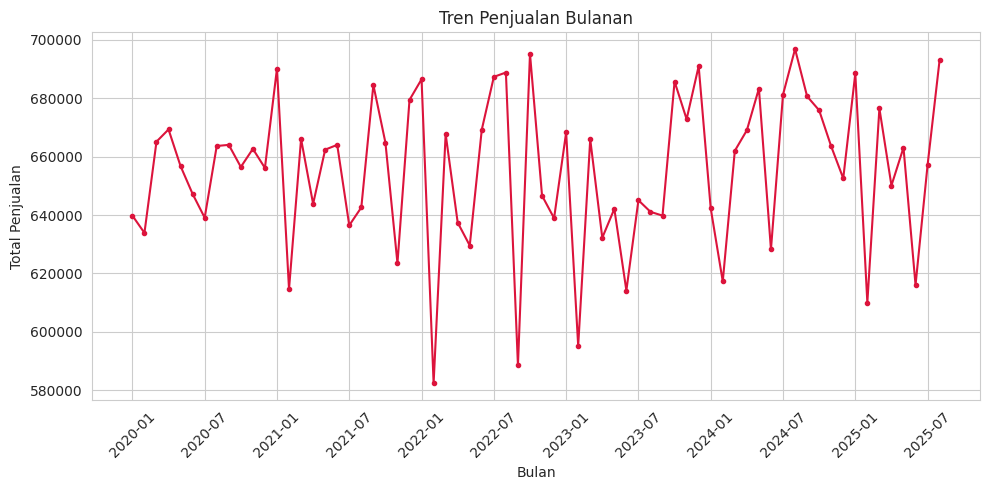

In [ ]:
tren = df.groupby('Bulan')['Total'].sum().iloc[:-1]   # bulan terakhir belum penuh

plt.figure(figsize=(10,5))
plt.plot(tren.index.astype(str), tren.values, marker='o', markersize=3, color='crimson')
idx = range(0, len(tren), 6)
plt.xticks(list(idx), [str(tren.index[i]) for i in idx], rotation=45)
plt.title('Tren Penjualan Bulanan')
plt.xlabel('Bulan')
plt.ylabel('Total Penjualan')
plt.tight_layout()
plt.show()

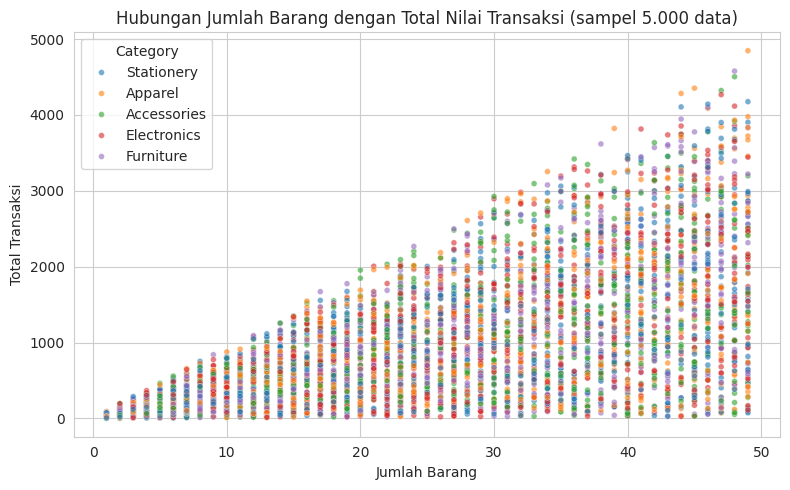

In [ ]:
sampel = df.sample(5000, random_state=42)

plt.figure(figsize=(8,5))
sns.scatterplot(data=sampel, x='Quantity', y='Total', hue='Category', alpha=0.6, s=18)
plt.title('Hubungan Jumlah Barang dengan Total Nilai Transaksi (sampel 5.000 data)')
plt.xlabel('Jumlah Barang')
plt.ylabel('Total Transaksi')
plt.tight_layout()
plt.show()

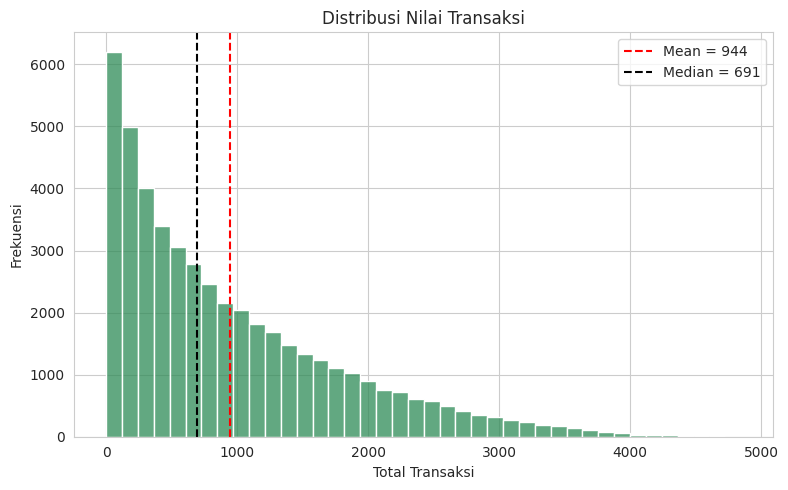

In [ ]:
plt.figure(figsize=(8,5))
sns.histplot(df['Total'], bins=40, color='seagreen')
plt.axvline(rata_trx, color='red', linestyle='--', label=f'Mean = {rata_trx:,.0f}')
plt.axvline(median_trx, color='black', linestyle='--', label=f'Median = {median_trx:,.0f}')
plt.legend()
plt.title('Distribusi Nilai Transaksi')
plt.xlabel('Total Transaksi')
plt.ylabel('Frekuensi')
plt.tight_layout()
plt.show()

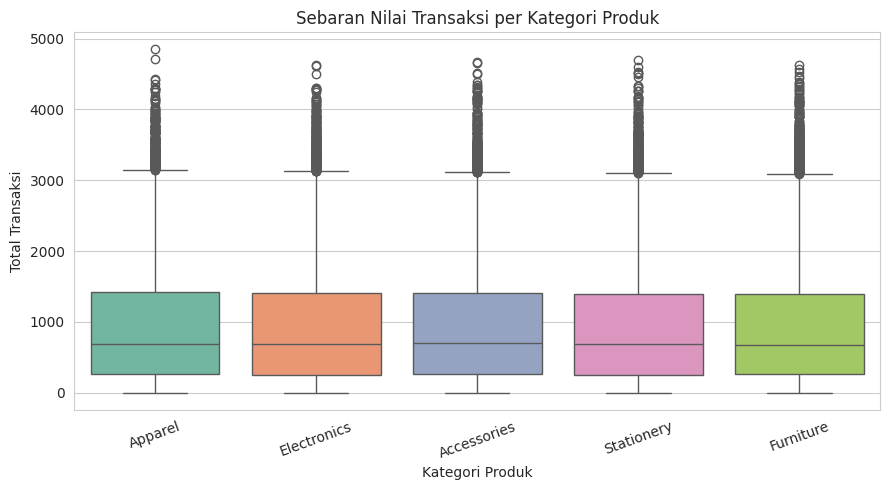

In [ ]:
plt.figure(figsize=(9,5))
sns.boxplot(data=df, x='Category', y='Total', hue='Category', palette='Set2', legend=False)
plt.title('Sebaran Nilai Transaksi per Kategori Produk')
plt.xlabel('Kategori Produk')
plt.ylabel('Total Transaksi')
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

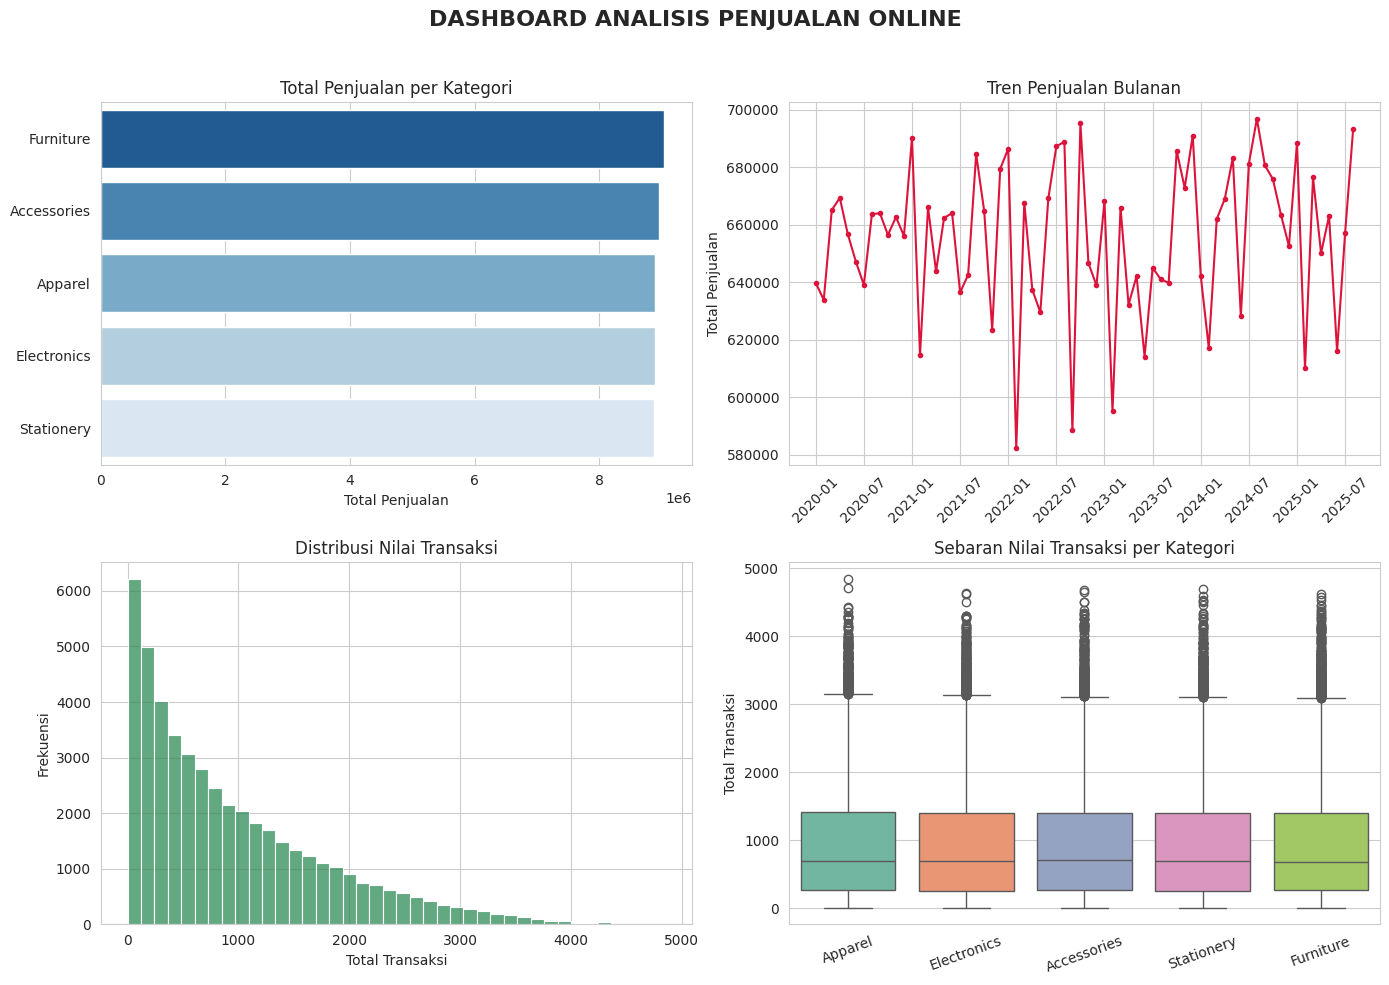

In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(14,10))

sns.barplot(x=per_kategori.values, y=per_kategori.index, hue=per_kategori.index,
            palette='Blues_r', legend=False, ax=axes[0,0])
axes[0,0].set_title('Total Penjualan per Kategori')
axes[0,0].set_xlabel('Total Penjualan'); axes[0,0].set_ylabel('')

axes[0,1].plot(tren.index.astype(str), tren.values, marker='o', markersize=3, color='crimson')
axes[0,1].set_title('Tren Penjualan Bulanan')
axes[0,1].set_xticks(list(idx))
axes[0,1].set_xticklabels([str(tren.index[i]) for i in idx], rotation=45)
axes[0,1].set_ylabel('Total Penjualan')

sns.histplot(df['Total'], bins=40, color='seagreen', ax=axes[1,0])
axes[1,0].set_title('Distribusi Nilai Transaksi')
axes[1,0].set_xlabel('Total Transaksi'); axes[1,0].set_ylabel('Frekuensi')

sns.boxplot(data=df, x='Category', y='Total', hue='Category', palette='Set2',
            legend=False, ax=axes[1,1])
axes[1,1].set_title('Sebaran Nilai Transaksi per Kategori')
axes[1,1].set_xlabel(''); axes[1,1].set_ylabel('Total Transaksi')
axes[1,1].tick_params(axis='x', rotation=20)

fig.suptitle('DASHBOARD ANALISIS PENJUALAN ONLINE', fontsize=16, fontweight='bold')
plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()